# 01 - Construct Validity: Does Rating Track Match Outcome?

Tests whether the rating tracks genuine performance, using match result as the one external criterion
that is not itself a rating. Five linked findings, each answering a question raised by the previous one.

**Two views of every result.** The live config is fitted on every career, so its ratings are in-sample
for all of them. Each analysis therefore runs twice on the same 217 matches:

| Split | Ratings from | Meaning |
|---|---|---|
| In-sample | the live config | what a user of the shipped config sees |
| Out-of-sample | a config fitted without the match's career (leave-one-career-out) | how the *procedure* generalises to a save it has not seen |

Only the out-of-sample rows are evidence about generalisation; the in-sample rows show fit. Folds are small
while few careers exist, so out-of-sample numbers are noisier. See `00_fit_stability` for how far the folds
differ from the live config.

**Pre-registered (original design, unchanged):** one-tailed Spearman test (H1: rho > 0), alpha = 0.05,
effect-size bands for |rho| (negligible < 0.1 <= weak < 0.3 <= moderate < 0.5 <= strong), with 0.3-0.5
expected as the "healthy" range set before any results were seen. Position groups, the xG tests and the
WM/CAM groups were added later and are exploratory; they sit in the Holm-Bonferroni family below.

**Not covered.** Goalkeepers have no independent outcome criterion (goals conceded is an input to their
rating), so they are not tested here; see `02_distributions` for their output. Wing-backs have no data.

In [1]:
from pathlib import Path
import json
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns

project_root = Path("..").resolve().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from workshop.lib import crossval, datasets, decompose, fit, gate, inference, rating, refit, sweep, variants
from workshop.lib.report import ci, header, say

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
from statsmodels.stats.multitest import multipletests

In [2]:
info = header()

**Validated config: `005d563f`** | run 2026-10-25

- Config fitted on: arsenal_2 1-38, ipswich_3 1-22, valencia_cf_1 1-157
- Data analysed (matches per career): arsenal_2 (38), ipswich_3 (22), valencia_cf_1 (157)

In [3]:
RANDOM_SEED = 42
ALPHA = 0.05
ALTERNATIVE = "greater"
N_BOOTSTRAP_RESAMPLES = 5000
EFFECT_SIZE_BANDS = {
    "negligible": (0.00, 0.10), "weak": (0.10, 0.30), "moderate": (0.30, 0.50), "strong": (0.50, 1.01),
}


def classify_effect_size(rho: float) -> str:
    return next((k for k, (lo, hi) in EFFECT_SIZE_BANDS.items() if lo <= abs(rho) < hi), "strong")


MIN_PLAYER_ROWS = 30
MIN_MATCHES = 10
KEYS = ["career", "match_id", "player_id"]
IN, OOS = "In-sample (live config)", "Out-of-sample (leave-one-career-out)"
SPLITS = [IN, OOS]

## 1. Data: both sets of ratings for every performance

In [4]:
configs = crossval.loco_configs()
base = rating.rated_performances("pool", column="rating_in")
base = base.merge(crossval.oos_ratings(configs), on=KEYS, validate="one_to_one")

nosup_in = rating.rated_performances(
    "pool", service=variants.no_supremacy_service(), column="nosup_in"
)[KEYS + ["nosup_in"]]
nosup_oos = pd.concat([
    rating.rated_performances(
        names=[career], service=variants.no_supremacy_service(directory), column="nosup_oos"
    )[KEYS + ["nosup_oos"]]
    for career, directory in configs.items()
])
base = base.merge(nosup_in, on=KEYS, validate="one_to_one").merge(nosup_oos, on=KEYS, validate="one_to_one")
base["match_key"] = base["career"] + ":" + base["match_id"].astype(str)
base["goal_diff"] = base["team_score"] - base["opp_score"]
base["xg_diff"] = base["team_xg"] - base["opp_xg"]
base["goals_for"] = base["team_score"]
base["defensive_value"] = -base["opp_score"]  # inverted so higher = better defending

perf = pd.concat([
    base.assign(split=IN, rating=base["rating_in"], rating_no_sup=base["nosup_in"]),
    base.assign(split=OOS, rating=base["rating_oos"], rating_no_sup=base["nosup_oos"]),
], ignore_index=True)

(perf.groupby("split")
     .agg(matches=("match_key", "nunique"), performances=("player_id", "size"), rated=("rating", "count"))
     .loc[SPLITS])

,matches,performances,rated
split,,,
In-sample (live config),217,3338,3259
Out-of-sample (leave-one-career-out),217,3338,3259


In [5]:
def team_frame(df: pd.DataFrame, outfield_only: bool, rating_col: str = "rating") -> pd.DataFrame:
    """One row per (split, match): average rating plus the match-level criteria."""
    rows = df[df["performance_type"] == "Outfield"] if outfield_only else df
    avg = (rows[rows[rating_col].notna()].groupby(["split", "match_key"])[rating_col].mean().rename("avg_rating"))
    context = df.groupby(["split", "match_key"]).first()[["career", "match_id", "goal_diff", "xg_diff"]]
    return context.join(avg, how="inner").reset_index()


def team_table(frame: pd.DataFrame, criterion: str) -> pd.DataFrame:
    """Team-average rating vs ``criterion`` for each split."""
    rows = []
    for split in SPLITS:
        f = frame[frame["split"] == split]
        test = stats.spearmanr(f["avg_rating"], f[criterion], alternative=ALTERNATIVE)
        boot = inference.bootstrap_spearman(f["avg_rating"], f[criterion], N_BOOTSTRAP_RESAMPLES, RANDOM_SEED)
        rows.append({
            "split": split, "n_matches": len(f), "rho": test.statistic, "p_value": test.pvalue,
            "ci_low": boot.ci_low, "ci_high": boot.ci_high, "se": boot.se,
            "effect_size": classify_effect_size(test.statistic), "significant": bool(test.pvalue < ALPHA),
        })
    return pd.DataFrame(rows).set_index("split")


team_all = team_frame(perf, outfield_only=False)
team_out = team_frame(perf, outfield_only=True)
print(f"{team_out['match_key'].nunique() if 'match_key' in team_out else len(team_out) // 2} matches with an outfield average")

217 matches with an outfield average


## Finding 1 - Team-Average Rating vs Goal Difference

Does the team-average rating correlate with goal difference? Reported for outfield players and, as a
robustness check, for all performances including goalkeepers.

In [6]:
print("ALL PERFORMANCES (GK + outfield)")
f1_all = team_table(team_all, "goal_diff")
display(f1_all)
print("OUTFIELD ONLY (GK excluded)")
f1_out = team_table(team_out, "goal_diff")
display(f1_out)

ALL PERFORMANCES (GK + outfield)


,n_matches,rho,p_value,ci_low,ci_high,se,effect_size,significant
split,,,,,,,,
In-sample (live config),217,0.689,0.000,0.605,0.759,0.040,strong,True
Out-of-sample (leave-one-career-out),217,0.604,0.000,0.505,0.689,0.047,strong,True


OUTFIELD ONLY (GK excluded)


,n_matches,rho,p_value,ci_low,ci_high,se,effect_size,significant
split,,,,,,,,
In-sample (live config),217,0.689,0.000,0.603,0.759,0.040,strong,True
Out-of-sample (leave-one-career-out),217,0.592,0.000,0.491,0.677,0.048,strong,True


In [7]:
rows = []
for split in SPLITS:
    for career in sorted(team_out["career"].unique()):
        f = team_out[(team_out["split"] == split) & (team_out["career"] == career)]
        test = stats.spearmanr(f["avg_rating"], f["goal_diff"], alternative=ALTERNATIVE)
        boot = inference.bootstrap_spearman(f["avg_rating"], f["goal_diff"], N_BOOTSTRAP_RESAMPLES, RANDOM_SEED)
        rows.append({"split": split, "career": career, "n_matches": len(f), "rho": test.statistic,
                     "ci_low": boot.ci_low, "ci_high": boot.ci_high, "p_value": test.pvalue})
f1_career = pd.DataFrame(rows).set_index(["split", "career"])
f1_career

n_matches   rho  ci_low  ci_high  p_value
split                                career                                                  
In-sample (live config)              arsenal_2             38 0.738   0.545    0.857    0.000
                                     ipswich_3             22 0.566   0.169    0.809    0.003
                                     valencia_cf_1        157 0.723   0.630    0.800    0.000
Out-of-sample (leave-one-career-out) arsenal_2             38 0.725   0.529    0.846    0.000
                                     ipswich_3             22 0.573   0.191    0.810    0.003
                                     valencia_cf_1        157 0.699   0.599    0.779    0.000

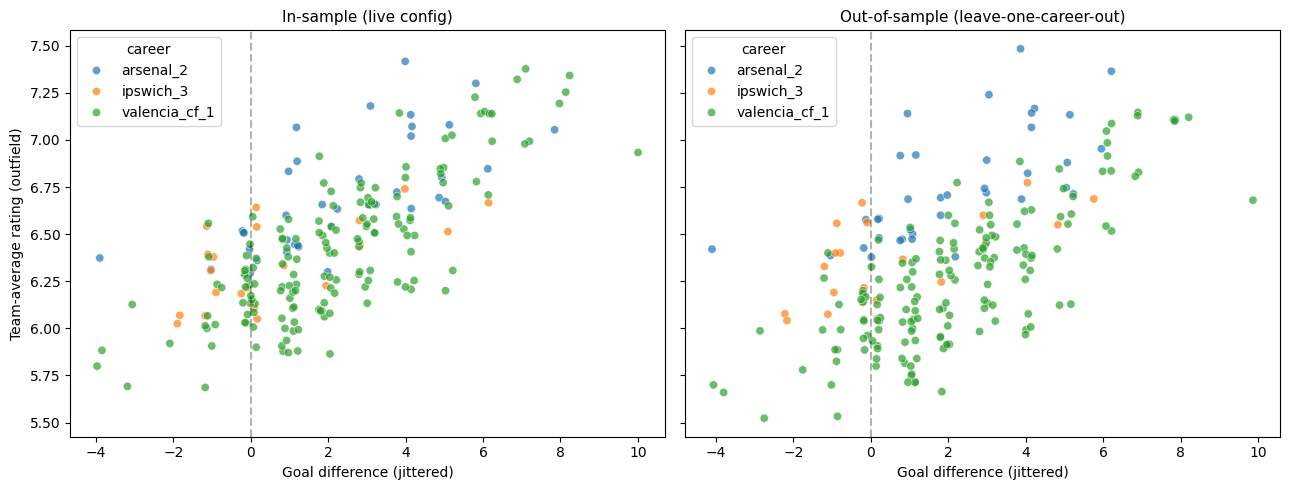

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
rng = np.random.default_rng(RANDOM_SEED)
for ax, split in zip(axes, SPLITS):
    d = team_out[team_out["split"] == split].copy()
    d["gd_jittered"] = d["goal_diff"] + rng.uniform(-0.25, 0.25, size=len(d))
    sns.scatterplot(data=d, x="gd_jittered", y="avg_rating", hue="career", alpha=0.7, ax=ax)
    ax.axvline(0, color="black", linestyle="--", alpha=0.3)
    ax.set_title(split, fontsize=11)
    ax.set_xlabel("Goal difference (jittered)")
axes[0].set_ylabel("Team-average rating (outfield)")
plt.tight_layout()
plt.show()

In [9]:
def band(r: float) -> str:
    return classify_effect_size(r)


gk_delta = {s: f1_all.loc[s, "rho"] - f1_out.loc[s, "rho"] for s in SPLITS}
career_in = f1_career.loc[IN]["rho"]
career_oos = f1_career.loc[OOS]["rho"]
say(
    f"**Team-average (outfield) rating vs goal difference:** rho = **{f1_out.loc[IN, 'rho']:.3f}** "
    f"[{f1_out.loc[IN, 'ci_low']:.3f}, {f1_out.loc[IN, 'ci_high']:.3f}] in-sample ({band(f1_out.loc[IN, 'rho'])}) and "
    f"**{f1_out.loc[OOS, 'rho']:.3f}** [{f1_out.loc[OOS, 'ci_low']:.3f}, {f1_out.loc[OOS, 'ci_high']:.3f}] "
    f"out-of-sample ({band(f1_out.loc[OOS, 'rho'])}). Including goalkeepers changes rho by "
    f"{gk_delta[IN]:+.3f} / {gk_delta[OOS]:+.3f}. By career, in-sample "
    + ", ".join(f"{c} {v:.3f}" for c, v in career_in.items())
    + "; out-of-sample "
    + ", ".join(f"{c} {v:.3f}" for c, v in career_oos.items())
    + f". The pre-registered 'healthy' range is 0.3 to 0.5; the in-sample estimate is "
    + ("above it." if f1_out.loc[IN, 'rho'] > 0.5 else "within it." if f1_out.loc[IN, 'rho'] >= 0.3 else "below it.")
)

**Team-average (outfield) rating vs goal difference:** rho = **0.689** [0.603, 0.759] in-sample (strong) and **0.592** [0.491, 0.677] out-of-sample (strong). Including goalkeepers changes rho by +0.000 / +0.012. By career, in-sample arsenal_2 0.738, ipswich_3 0.566, valencia_cf_1 0.723; out-of-sample arsenal_2 0.725, ipswich_3 0.573, valencia_cf_1 0.699. The pre-registered 'healthy' range is 0.3 to 0.5; the in-sample estimate is above it.

## Finding 2 - Decorrelation Against xG Differential

The supremacy scalar exists to neutralise rating's relationship with **xG dominance**, not goal difference. The
test is repeated against xG differential, then with the scalar switched off (`workshop/lib/variants.py`).

Every exploratory test from here on is recorded for the joint multiple-comparisons correction at the end.

In [10]:
exploratory = []


def record_test(label: str, split: str, rho: float, p_value: float, group: str | None = None) -> None:
    exploratory.append({"test": label, "split": split, "group": group, "rho": rho, "p_value": p_value})


gd_xg = {s: stats.spearmanr(g["goal_diff"], g["xg_diff"]).statistic for s, g in team_out.groupby("split")}
f2_real = team_table(team_out, "xg_diff")
team_nosup = team_frame(perf, outfield_only=True, rating_col="rating_no_sup")
f2_nosup = team_table(team_nosup, "xg_diff")
for split, row in f2_real.iterrows():
    record_test("Rating vs xG differential", split, row["rho"], row["p_value"])
for split, row in f2_nosup.iterrows():
    record_test("No-supremacy rating vs xG differential", split, row["rho"], row["p_value"])

display(pd.DataFrame({
    "rho(goal diff, xG diff)": pd.Series(gd_xg),
    "real rating vs xG": f2_real["rho"],
    "no-supremacy vs xG": f2_nosup["rho"],
    "delta (no-sup - real)": f2_nosup["rho"] - f2_real["rho"],
}).loc[SPLITS])

,"rho(goal diff, xG diff)",real rating vs xG,no-supremacy vs xG,delta (no-sup - real)
In-sample (live config),0.684,0.544,0.687,0.142
Out-of-sample (leave-one-career-out),0.684,0.425,0.589,0.164


In [11]:
paired = team_out.merge(
    team_nosup[["split", "match_key", "avg_rating"]].rename(columns={"avg_rating": "avg_no_sup"}),
    on=["split", "match_key"], validate="one_to_one",
)
rows = []
for split in SPLITS:
    f = paired[paired["split"] == split]
    est = inference.paired_delta_rho(f["avg_rating"], f["avg_no_sup"], f["xg_diff"], N_BOOTSTRAP_RESAMPLES, RANDOM_SEED)
    rows.append({"split": split, "n_matches": len(f), "delta_rho": est.estimate, "ci_low": est.ci_low,
                 "ci_high": est.ci_high, "se": est.se, "p_value": est.p_one_tailed})
    record_test("Delta rho (no-supremacy - real) vs xG differential", split, est.estimate, est.p_one_tailed)
f2_delta = pd.DataFrame(rows).set_index("split")
f2_delta

,n_matches,delta_rho,ci_low,ci_high,se,p_value
split,,,,,,
In-sample (live config),217,0.142,0.108,0.181,0.019,0.000
Out-of-sample (leave-one-career-out),217,0.164,0.127,0.205,0.020,0.000


In [12]:
say(
    f"**xG differential:** rating correlates at **{f2_real.loc[IN, 'rho']:.3f}** [{f2_real.loc[IN, 'ci_low']:.3f}, {f2_real.loc[IN, 'ci_high']:.3f}] "
    f"in-sample and **{f2_real.loc[OOS, 'rho']:.3f}** [{f2_real.loc[OOS, 'ci_low']:.3f}, {f2_real.loc[OOS, 'ci_high']:.3f}] out-of-sample "
    f"(goal difference itself correlates with xG difference at {gd_xg[IN]:.3f} / {gd_xg[OOS]:.3f}). Switching the supremacy scalar off raises "
    f"the correlation by **{f2_delta.loc[IN, 'delta_rho']:+.3f}** [{f2_delta.loc[IN, 'ci_low']:+.3f}, {f2_delta.loc[IN, 'ci_high']:+.3f}] in-sample and "
    f"**{f2_delta.loc[OOS, 'delta_rho']:+.3f}** [{f2_delta.loc[OOS, 'ci_low']:+.3f}, {f2_delta.loc[OOS, 'ci_high']:+.3f}] out-of-sample, to "
    f"{f2_nosup.loc[IN, 'rho']:.3f} / {f2_nosup.loc[OOS, 'rho']:.3f}. "
    + ("Both intervals exclude zero, so the scalar does remove xG coupling." if (f2_delta['ci_low'] > 0).all()
       else "At least one interval includes zero, so the scalar's effect is not established on every split.")
    + f" The coupling that remains with the scalar off ({f2_nosup['rho'].min():.2f} to {f2_nosup['rho'].max():.2f}) comes from the rest of the pipeline."
)

**xG differential:** rating correlates at **0.544** [0.432, 0.643] in-sample and **0.425** [0.299, 0.537] out-of-sample (goal difference itself correlates with xG difference at 0.684 / 0.684). Switching the supremacy scalar off raises the correlation by **+0.142** [+0.108, +0.181] in-sample and **+0.164** [+0.127, +0.205] out-of-sample, to 0.687 / 0.589. Both intervals exclude zero, so the scalar does remove xG coupling. The coupling that remains with the scalar off (0.59 to 0.69) comes from the rest of the pipeline.

## Finding 3 - Player Level vs Team Level

Does the team-level result hold at the grain the algorithm works at (one player, one match), or is it partly
an averaging artefact? Rows from the same match share a scoreline, so the bootstrap resamples whole matches.

In [13]:
players = perf[(perf["performance_type"] == "Outfield") & perf["rating"].notna()].copy()
rows = []
for split in SPLITS:
    sub = players[players["split"] == split]
    est = inference.cluster_bootstrap_spearman(sub["rating"], sub["goal_diff"], sub["match_key"], N_BOOTSTRAP_RESAMPLES, RANDOM_SEED)
    rows.append({"split": split, "n_matches": sub["match_key"].nunique(), "n_players": len(sub), "player_rho": est.estimate,
                 "ci_low": est.ci_low, "ci_high": est.ci_high, "p_value": est.p_one_tailed, "team_rho": f1_out.loc[split, "rho"]})
    record_test("Player-level rating vs GD", split, est.estimate, est.p_one_tailed)
f3 = pd.DataFrame(rows).set_index("split")
f3["gap_team_minus_player"] = f3["team_rho"] - f3["player_rho"]
f3

,n_matches,n_players,player_rho,ci_low,ci_high,p_value,team_rho,gap_team_minus_player
split,,,,,,,,
In-sample (live config),217,3042,0.247,0.203,0.289,0.000,0.689,0.442
Out-of-sample (leave-one-career-out),217,3042,0.224,0.174,0.271,0.000,0.592,0.368


In [14]:
say(
    f"**Player level:** rho = **{f3.loc[IN, 'player_rho']:.3f}** [{f3.loc[IN, 'ci_low']:.3f}, {f3.loc[IN, 'ci_high']:.3f}] in-sample and "
    f"**{f3.loc[OOS, 'player_rho']:.3f}** [{f3.loc[OOS, 'ci_low']:.3f}, {f3.loc[OOS, 'ci_high']:.3f}] out-of-sample, against team-level "
    f"{f3.loc[IN, 'team_rho']:.3f} / {f3.loc[OOS, 'team_rho']:.3f}. The team-minus-player gap is {f3.loc[IN, 'gap_team_minus_player']:.2f} / "
    f"{f3.loc[OOS, 'gap_team_minus_player']:.2f}, so most of the team-level strength comes from averaging many players "
    f"({band(f3.loc[IN, 'player_rho'])} band at the player grain in-sample)."
)

**Player level:** rho = **0.247** [0.203, 0.289] in-sample and **0.224** [0.174, 0.271] out-of-sample, against team-level 0.689 / 0.592. The team-minus-player gap is 0.44 / 0.37, so most of the team-level strength comes from averaging many players (weak band at the player grain in-sample).

## Finding 4 - Position Groups

Pooling positions can hide structure: an attacker's rating should respond to goals scored differently from a
centre-back's. Groups use the *first listed* position (a descriptive simplification, not the service's multi-position
blend); wing-backs have no data. Groups below `MIN_PLAYER_ROWS` rows or `MIN_MATCHES` matches in a split are skipped.

In [15]:
POSITION_GROUP_MAP = {
    "ST": "ST", "LW": "Winger", "RW": "Winger", "LM": "WM", "RM": "WM", "CAM": "CAM",
    "CM": "CM", "CDM": "CDM", "CB": "CB", "LB": "Fullback", "RB": "Fullback",
}
ORIGINAL_GROUPS = ["CB", "CDM", "CM", "Fullback", "ST", "Winger"]
NEW_GROUPS = ["WM", "CAM"]
players["position_group"] = players["primary_position"].map(POSITION_GROUP_MAP)
players.pivot_table(index="position_group", columns="split", values="rating", aggfunc="count", fill_value=0)[SPLITS]

split,In-sample (live config),Out-of-sample (leave-one-career-out)
position_group,,
CAM,29,29
CB,579,579
CDM,330,330
CM,570,570
Fullback,568,568
ST,333,333
WM,72,72
Winger,561,561


In [16]:
def group_estimate(split: str, group: str, criterion: str):
    sub = players[(players["split"] == split) & (players["position_group"] == group)]
    if len(sub) < MIN_PLAYER_ROWS or sub["match_key"].nunique() < MIN_MATCHES:
        return None, len(sub)
    est = inference.cluster_bootstrap_spearman(sub["rating"], sub[criterion], sub["match_key"], N_BOOTSTRAP_RESAMPLES, RANDOM_SEED)
    return est, len(sub)


def group_table(groups: list[str], criterion_for) -> pd.DataFrame:
    rows = []
    for group in groups:
        for split in SPLITS:
            criterion = criterion_for(group)
            est, n = group_estimate(split, group, criterion)
            row = {"group": group, "split": split, "criterion": criterion, "n": n}
            if est is not None:
                row.update(rho=est.estimate, ci_low=est.ci_low, ci_high=est.ci_high, p_value=est.p_one_tailed)
                record_test(f"{group} rating vs {criterion}", split, est.estimate, est.p_one_tailed, group=group)
            rows.append(row)
    return pd.DataFrame(rows)


f4 = group_table(ORIGINAL_GROUPS + NEW_GROUPS, lambda g: "goal_diff")
display(f4.pivot(index="group", columns="split", values="rho")[SPLITS])
f4[["group", "split", "n", "rho", "ci_low", "ci_high", "p_value"]].round(3)

split,In-sample (live config),Out-of-sample (leave-one-career-out)
group,,
CAM,NaN,NaN
CB,0.200,0.190
CDM,0.249,0.247
CM,0.339,0.322
Fullback,0.143,0.110
ST,0.251,0.231
WM,0.147,0.139
Winger,0.323,0.317


,group,split,n,rho,ci_low,ci_high,p_value
0,CB,In-sample (live config),579,0.200,0.108,0.290,0.000
1,CB,Out-of-sample (leave-one-career-out),579,0.190,0.096,0.281,0.000
2,CDM,In-sample (live config),330,0.249,0.153,0.344,0.000
3,CDM,Out-of-sample (leave-one-career-out),330,0.247,0.150,0.343,0.000
4,CM,In-sample (live config),570,0.339,0.258,0.414,0.000
5,CM,Out-of-sample (leave-one-career-out),570,0.322,0.234,0.401,0.000
6,Fullback,In-sample (live config),568,0.143,0.063,0.221,0.000
7,Fullback,Out-of-sample (leave-one-career-out),568,0.110,0.028,0.191,0.003
8,ST,In-sample (live config),333,0.251,0.150,0.348,0.000
9,ST,Out-of-sample (leave-one-career-out),333,0.231,0.129,0.330,0.000


In [17]:
def compare_groups(table: pd.DataFrame, label: str) -> str:
    """Describe in-sample vs out-of-sample rho for each group in ``table``."""
    parts, flagged_zero, flagged_gap = [], [], []
    for key, g in table.groupby(["group", "criterion"], sort=False):
        g = g.set_index("split")
        if not {IN, OOS} <= set(g.index) or g.loc[[IN, OOS], "rho"].isna().any():
            continue
        name = key[0] if label == "GD" else f"{key[0]} ({key[1]})"
        a, b = g.loc[IN, "rho"], g.loc[OOS, "rho"]
        parts.append(f"{name} {a:.2f} / {b:.2f}")
        if g.loc[OOS, "ci_low"] <= 0 <= g.loc[OOS, "ci_high"]:
            flagged_zero.append(name)
        if abs(a - b) >= 0.15:
            flagged_gap.append(name)
    skipped = sorted(set(table.loc[table["rho"].isna(), "group"]))
    return (
        "In-sample / out-of-sample rho: " + "; ".join(parts) + ". "
        + (f"Out-of-sample interval includes zero for: {', '.join(flagged_zero)}. " if flagged_zero else "Every out-of-sample interval excludes zero. ")
        + (f"In-sample and out-of-sample differ by 0.15 or more for: {', '.join(flagged_gap)}. " if flagged_gap else "")
        + (f"Too few rows to test: {', '.join(skipped)}." if skipped else "")
    )


say("**Position groups vs goal difference.** " + compare_groups(f4, "GD"))

**Position groups vs goal difference.** In-sample / out-of-sample rho: CB 0.20 / 0.19; CDM 0.25 / 0.25; CM 0.34 / 0.32; Fullback 0.14 / 0.11; ST 0.25 / 0.23; Winger 0.32 / 0.32; WM 0.15 / 0.14. Out-of-sample interval includes zero for: WM. Too few rows to test: CAM.

### Position-Appropriate Criteria

Goal difference conflates two constructs. Attacking output (ST, Winger, CM, WM, CAM) should track `goals_for`;
defensive output (CB, Fullback) should track goals against, inverted (`defensive_value`) so a positive rho still
means "better rating, better defending". CDM straddles both and is tested against each.

In [18]:
CRITERION_MAP = {
    "ST": "goals_for", "Winger": "goals_for", "CM": "goals_for", "WM": "goals_for", "CAM": "goals_for",
    "CB": "defensive_value", "Fullback": "defensive_value",
}
f5_single = group_table(list(CRITERION_MAP), lambda g: CRITERION_MAP[g])
f5_cdm = pd.concat([group_table(["CDM"], lambda g, c=c: c) for c in ("goals_for", "defensive_value")])
f5 = pd.concat([f5_single, f5_cdm], ignore_index=True)
f5[["group", "criterion", "split", "n", "rho", "ci_low", "ci_high", "p_value"]].round(3)

,group,criterion,split,n,rho,ci_low,ci_high,p_value
0,ST,goals_for,In-sample (live config),333,0.362,0.266,0.454,0.000
1,ST,goals_for,Out-of-sample (leave-one-career-out),333,0.366,0.268,0.460,0.000
2,Winger,goals_for,In-sample (live config),561,0.366,0.277,0.448,0.000
3,Winger,goals_for,Out-of-sample (leave-one-career-out),561,0.368,0.272,0.453,0.000
4,CM,goals_for,In-sample (live config),570,0.316,0.234,0.392,0.000
5,CM,goals_for,Out-of-sample (leave-one-career-out),570,0.316,0.230,0.393,0.000
6,WM,goals_for,In-sample (live config),72,0.036,-0.271,0.349,0.408
7,WM,goals_for,Out-of-sample (leave-one-career-out),72,0.026,-0.279,0.343,0.429
8,CAM,goals_for,In-sample (live config),29,NaN,NaN,NaN,NaN
9,CAM,goals_for,Out-of-sample (leave-one-career-out),29,NaN,NaN,NaN,NaN


In [19]:
say("**Position-appropriate criteria.** " + compare_groups(f5, "criterion"))

**Position-appropriate criteria.** In-sample / out-of-sample rho: ST (goals_for) 0.36 / 0.37; Winger (goals_for) 0.37 / 0.37; CM (goals_for) 0.32 / 0.32; WM (goals_for) 0.04 / 0.03; CB (defensive_value) 0.28 / 0.27; Fullback (defensive_value) 0.22 / 0.16; CDM (goals_for) 0.19 / 0.19; CDM (defensive_value) 0.24 / 0.23. Out-of-sample interval includes zero for: WM (goals_for). Too few rows to test: CAM.

## Multiple-Comparisons Correction

Holm-Bonferroni across every exploratory test recorded above, reported with and without the later-added WM and
CAM groups.

In [20]:
results = pd.DataFrame(exploratory)


def holm(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    reject, corrected, _, _ = multipletests(out["p_value"], alpha=ALPHA, method="holm")
    out["p_corrected"] = corrected
    out["significant_raw"] = out["p_value"] < ALPHA
    out["significant_corrected"] = reject
    return out


family_a = holm(results[~results["group"].isin(NEW_GROUPS)])
family_b = holm(results)
summary = pd.DataFrame({
    "tests": [len(family_a), len(family_b)],
    "significant_raw": [family_a["significant_raw"].sum(), family_b["significant_raw"].sum()],
    "significant_after_holm": [family_a["significant_corrected"].sum(), family_b["significant_corrected"].sum()],
}, index=["without WM/CAM", "everything"])
display(summary)
family_b.sort_values("p_value")[["test", "split", "rho", "p_value", "p_corrected", "significant_corrected"]].round(4)

,tests,significant_raw,significant_after_holm
without WM/CAM,34,34,34
everything,38,34,34


,test,split,rho,p_value,p_corrected,significant_corrected
7,Player-level rating vs GD,Out-of-sample (leave-one-career-out),0.224,0.000,0.000,True
6,Player-level rating vs GD,In-sample (live config),0.247,0.000,0.000,True
5,Delta rho (no-supremacy - real) vs xG differen...,Out-of-sample (leave-one-career-out),0.164,0.000,0.000,True
4,Delta rho (no-supremacy - real) vs xG differen...,In-sample (live config),0.142,0.000,0.000,True
11,CDM rating vs goal_diff,Out-of-sample (leave-one-career-out),0.246,0.000,0.000,True
10,CDM rating vs goal_diff,In-sample (live config),0.249,0.000,0.000,True
9,CB rating vs goal_diff,Out-of-sample (leave-one-career-out),0.190,0.000,0.000,True
8,CB rating vs goal_diff,In-sample (live config),0.200,0.000,0.000,True
12,CM rating vs goal_diff,In-sample (live config),0.339,0.000,0.000,True
13,CM rating vs goal_diff,Out-of-sample (leave-one-career-out),0.322,0.000,0.000,True


In [21]:
failed = family_b[~family_b["significant_corrected"]]
by_split = family_b.groupby("split")["significant_corrected"].agg(["sum", "size"])
by_group_fail = failed.assign(group=failed["group"].fillna("overall")).groupby("group").size().sort_values(ascending=False)
say(
    f"**Multiple comparisons.** Of {len(family_b)} tests, {int(family_b['significant_raw'].sum())} are significant uncorrected and "
    f"**{int(family_b['significant_corrected'].sum())}** survive Holm-Bonferroni. In-sample {int(by_split.loc[IN, 'sum'])} of {int(by_split.loc[IN, 'size'])} "
    f"survive; out-of-sample {int(by_split.loc[OOS, 'sum'])} of {int(by_split.loc[OOS, 'size'])}. "
    + (f"The {len(failed)} that fail are concentrated in: " + ", ".join(f"{g} ({n})" for g, n in by_group_fail.items()) + "." if len(failed) else "None fail.")
)

**Multiple comparisons.** Of 38 tests, 34 are significant uncorrected and **34** survive Holm-Bonferroni. In-sample 17 of 19 survive; out-of-sample 17 of 19. The 4 that fail are concentrated in: WM (4).

## Notes and limitations

- Position groups use the first listed position; multi-position players are counted once.
- The one-tailed bootstrap p-value is the share of resamples with a statistic <= 0, so its resolution is 1 / 5,000 and
  0.0000 means none of 5,000 resamples.
- Out-of-sample folds are fitted on fewer matches than the live config; the Valencia fold sees only the two smaller careers.
- Position cells in Arsenal and Ipswich are small; groups below the minimum are skipped, not estimated.
- This notebook speaks to construct validity only; stability, distributions, goals, reliability and sensitivity have their own notebooks.

In [22]:
say(
    f"**Summary (config `{info['hash'][:8]}`).** Team-level rho with goal difference is {f1_out.loc[IN, 'rho']:.2f} in-sample and "
    f"{f1_out.loc[OOS, 'rho']:.2f} out-of-sample; player-level {f3.loc[IN, 'player_rho']:.2f} and {f3.loc[OOS, 'player_rho']:.2f}. "
    f"{int(family_b['significant_corrected'].sum())} of {len(family_b)} position-level and supporting tests survive correction."
)

**Summary (config `005d563f`).** Team-level rho with goal difference is 0.69 in-sample and 0.59 out-of-sample; player-level 0.25 and 0.22. 34 of 38 position-level and supporting tests survive correction.